<a href="https://colab.research.google.com/github/Arjunanand717/EXP--7/blob/main/EXP_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PART A

In [19]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
import os

# Configure student roll number
ROLL_NO = "24BAD401"

print("Student Roll No:", ROLL_NO)
print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

Student Roll No: 24BAD401
TensorFlow Version: 2.21.0
GPU Available: []


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/mnist/incomplete.V0647X_3.0.1/mnist-train.tfrecord-[0-9][0-9][0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/mnist/incomplete.V0647X_3.0.1/mnist-test.tfrecord-[0-9][0-9][0-9][0-9][0-9…

Dataset mnist downloaded and prepared to /root/tensorflow_datasets/mnist/3.0.1. Subsequent calls will reuse this data.


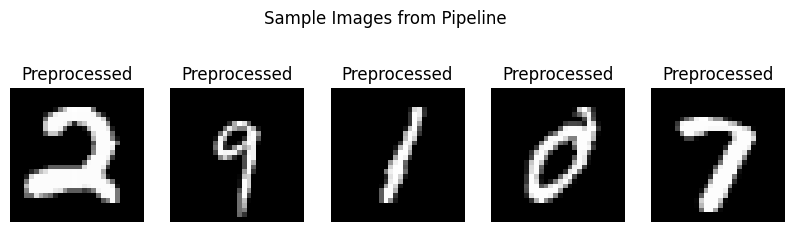

In [22]:
# Install missing dependency and prepare dataset
!pip install -q importlib_resources

import tensorflow_datasets as tfds
import tensorflow as tf
import matplotlib.pyplot as plt

BUFFER_SIZE = 60000
BATCH_SIZE = 256
LATENT_DIM = 100

# 1. Load the MNIST dataset
ds, ds_info = tfds.load('mnist', split='train', with_info=True, as_supervised=True)

# 2. Normalize images from [0, 255] to [-1.0, 1.0]
def preprocess_img(image, label):
    image = tf.cast(image, tf.float32)
    image = (image - 127.5) / 127.5
    return image

# 3. Build tf.data pipeline
train_dataset = ds.map(preprocess_img, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# 4. Display 5 preprocessed sample images
plt.figure(figsize=(10, 3))
for images in train_dataset.take(1):
    for i in range(5):
        plt.subplot(1, 5, i+1)
        plt.imshow(images[i, :, :, 0], cmap='gray')
        plt.title("Preprocessed")
        plt.axis('off')
plt.suptitle("Sample Images from Pipeline")
plt.show()

PART B

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_15 (LeakyReLU)      │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_16 (LeakyReLU)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_10             │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

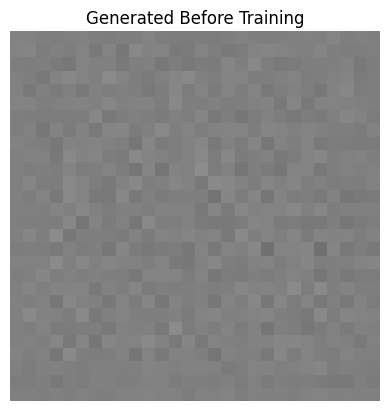

Student Roll No: 24BAD401


In [23]:

from tensorflow.keras import layers, Model

LATENT_DIM = 100

def build_generator():
    model = tf.keras.Sequential([
        layers.Input(shape=(LATENT_DIM,)),
        layers.Dense(7 * 7 * 128, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Reshape((7, 7, 128)),

        layers.Conv2DTranspose(
            64, 4, strides=2, padding='same', use_bias=False
        ),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(
            1, 4, strides=2, padding='same', activation='tanh'
        )
    ], name="Generator")
    return model

generator = build_generator()
generator.summary()

# Generate an image before training
noise = tf.random.normal([1, LATENT_DIM])
generated_image = generator(noise, training=False)

plt.imshow(generated_image[0, :, :, 0], cmap='gray',
           vmin=-1, vmax=1)
plt.title("Generated Before Training")
plt.axis('off')
plt.show()

print("Student Roll No:", ROLL_NO)

PART C

In [25]:
def build_discriminator():
    model = tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ], name="Discriminator")
    return model

discriminator = build_discriminator()
discriminator.summary()

# Loss and Optimizer setup
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

print("Part C setup successfully configured.")

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_19 (LeakyReLU)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_20 (LeakyReLU)      │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

Part C setup successfully configured.


In [35]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# Clear previous graph state
tf.keras.backend.clear_session()

def build_discriminator():
    model = tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(64, 4, strides=2, padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, 4, strides=2, padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)  # Real/fake logit
    ], name="Discriminator")
    return model

# Re-build models as fully trainable
generator = build_generator()
discriminator = build_discriminator()

generator.trainable = True
discriminator.trainable = True

print("Models rebuilt as trainable.")

Models rebuilt as trainable.


In [36]:
import tensorflow as tf

# Setup loss & optimizers anew
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

def generate_and_save_images(model, epoch, test_input):
    predictions = model(test_input, training=False)
    fig = plt.figure(figsize=(4, 4))
    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i+1)
        plt.imshow(predictions[i, :, :, 0] * 127.5 + 127.5, cmap='gray')
        plt.axis('off')
    plt.suptitle(f"Generated Images at Epoch {epoch}")
    plt.show()

Starting training for 5 epochs...
Epoch 1 complete in 316.05 sec | Gen Loss: 1.3138 | Disc Loss: 0.7452


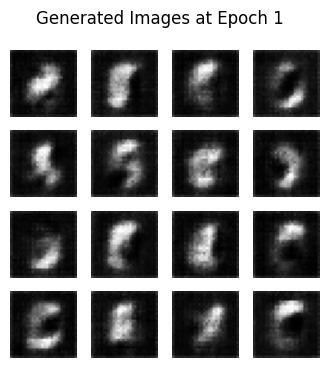

Epoch 2 complete in 307.46 sec | Gen Loss: 0.9343 | Disc Loss: 1.1281


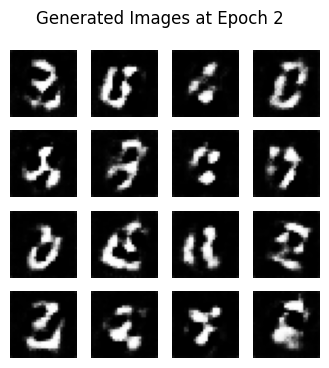

Epoch 3 complete in 312.92 sec | Gen Loss: 0.8515 | Disc Loss: 1.2591


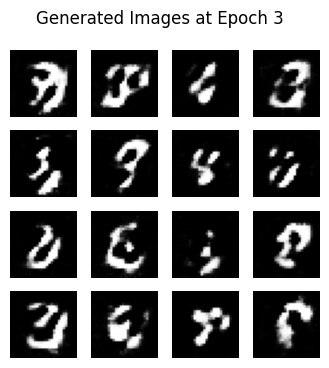

Epoch 4 complete in 315.19 sec | Gen Loss: 0.8305 | Disc Loss: 1.2786


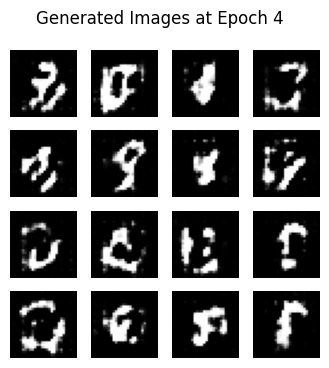

Epoch 5 complete in 318.81 sec | Gen Loss: 0.8290 | Disc Loss: 1.2816


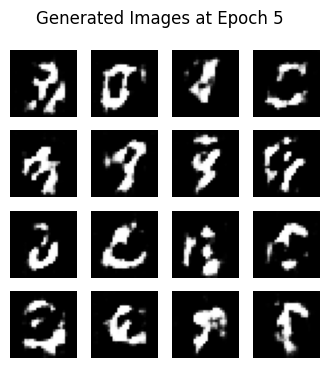

In [37]:
import time
import numpy as np

# Re-initialize the optimizers to clean up any tracked state conflicts
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

# Ensure models are fully trainable
generator.trainable = True
discriminator.trainable = True

EPOCHS = 5
seed = tf.random.normal([16, LATENT_DIM])
gen_losses = []
disc_losses = []

print(f"Starting training for {EPOCHS} epochs...")
for epoch in range(1, EPOCHS + 1):
    start = time.time()
    epoch_gen_loss = []
    epoch_disc_loss = []

    for image_batch in train_dataset:
        if image_batch.shape[0] == BATCH_SIZE:
            g_loss, d_loss = train_step(image_batch)
            epoch_gen_loss.append(g_loss.numpy())
            epoch_disc_loss.append(d_loss.numpy())

    avg_gen = np.mean(epoch_gen_loss)
    avg_disc = np.mean(epoch_disc_loss)
    gen_losses.append(avg_gen)
    disc_losses.append(avg_disc)

    print(f'Epoch {epoch} complete in {time.time()-start:.2f} sec | Gen Loss: {avg_gen:.4f} | Disc Loss: {avg_disc:.4f}')
    generate_and_save_images(generator, epoch, seed)

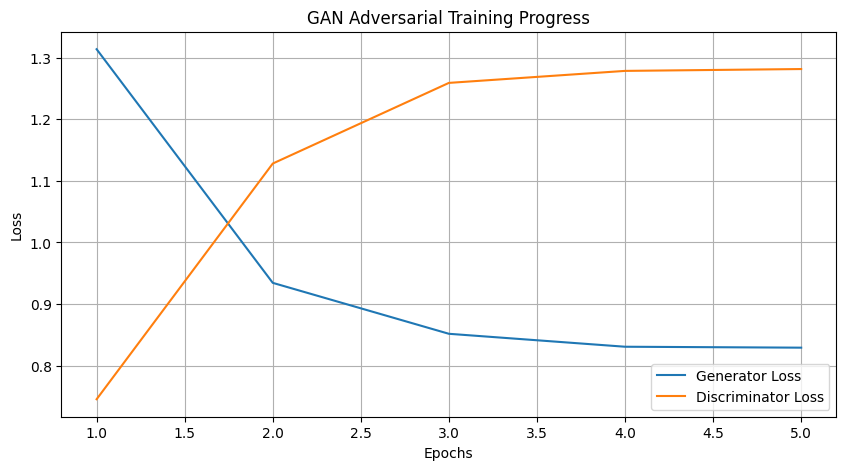

Student Roll No: 24BAD401


In [38]:
# Plot the loss progression curves
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(gen_losses) + 1), gen_losses, label="Generator Loss")
plt.plot(range(1, len(disc_losses) + 1), disc_losses, label="Discriminator Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("GAN Adversarial Training Progress")
plt.legend()
plt.grid(True)
plt.show()
